In [ ]:
# Cell 1: setup and imports
import os
import math
import random
from pathlib import Path
from typing import Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, precision_recall_curve, auc

# Set deterministic-ish behavior
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


Device: cuda


In [ ]:
# Cell 2: load creditcard.csv, basic preprocessing, sliding-window construction
# Upload creditcard.csv to Colab. Assumes columns: Time, V1..V28, Amount, Class
DATA_PATH = "/content/creditcard.csv"
assert os.path.exists(DATA_PATH), "Please upload creditcard.csv to the working directory."

df = pd.read_csv(DATA_PATH)
print("Loaded shape:", df.shape)

# Sort by Time to impose sequence ordering
df = df.sort_values("Time").reset_index(drop=True)

# Select features for modeling (exclude 'Class')
feat_cols = [c for c in df.columns if c not in ("Class",)]
# We'll use V1..V28 and Amount (Time kept for sequence ordering)
feature_names = [c for c in feat_cols if c != "Time"]
print("Features used:", feature_names[:5], "...", len(feature_names))

# Standardize features (fit on whole dataset - in production fit only on train)
scaler = StandardScaler()
df[feature_names] = scaler.fit_transform(df[feature_names])

# Build sliding windows to convert transactions into short multivariate sequences.
# Choose window size (number of consecutive transactions)
WINDOW = 8  # you can change (8 recommended for quick runs)
STEP = 1

def make_windows(df: pd.DataFrame, window: int, step: int, feature_names=feature_names):
    X = []
    y = []
    times = []
    for start in range(0, len(df) - window + 1, step):
        window_df = df.iloc[start:start+window]
        X.append(window_df[feature_names].values.astype(np.float32))  # shape (window, features)
        y.append(int(window_df['Class'].any()))  # label sequence is anomalous if any transaction in window is fraud
        times.append(float(window_df['Time'].iloc[-1]))
    X = np.stack(X)
    y = np.array(y, dtype=np.int64)
    times = np.array(times, dtype=np.float32)
    return X, y, times

X, y, times = make_windows(df, WINDOW, STEP)
print("Windows:", X.shape, y.sum(), "anomalous windows out of", len(y))


Loaded shape: (284807, 31)
Features used: ['V1', 'V2', 'V3', 'V4', 'V5'] ... 29
Windows: (284800, 8, 29) 3589 anomalous windows out of 284800


In [ ]:
# Cell 3: PyTorch Dataset and augmentations (geometric masking)
class TimeSeriesWindows(Dataset):
    def __init__(self, X: np.ndarray, y: np.ndarray, augment=True):
        """
        X: (N, T, F)
        y: (N,)
        """
        self.X = X
        self.y = y
        self.augment = augment
        self.N, self.T, self.F = X.shape

    def __len__(self):
        return self.N

    def geometric_mask(self, x: np.ndarray) -> np.ndarray:
        """
        Geometric masking:
        - random contiguous time-mask (drop entire time steps)
        - random feature dropout (mask random subset of features across all timesteps)
        - random magnitude scaling on a contiguous block (simulating occlusion/shift)
        """
        x = x.copy()
        # time mask
        if random.random() < 0.5:
            t_len = random.randint(1, max(1, self.T//3))
            t0 = random.randint(0, self.T - t_len)
            x[t0:t0+t_len, :] = 0.0

        # feature dropout
        if random.random() < 0.5:
            f_count = random.randint(1, max(1, self.F//5))
            f_idx = random.sample(range(self.F), f_count)
            x[:, f_idx] = 0.0

        # magnitude jitter on contiguous time block
        if random.random() < 0.5:
            t_len = random.randint(1, max(1, self.T//4))
            t0 = random.randint(0, self.T - t_len)
            scale = 1.0 + np.random.normal(0, 0.3)
            x[t0:t0+t_len, :] = x[t0:t0+t_len, :] * scale

        # add small gaussian noise
        x += np.random.normal(0, 0.01, x.shape).astype(np.float32)
        return x

    def __getitem__(self, idx):
        x = self.X[idx]
        y = self.y[idx]
        if self.augment:
            x1 = self.geometric_mask(x)
            x2 = self.geometric_mask(x)
            return x.astype(np.float32), x1.astype(np.float32), x2.astype(np.float32), y
        else:
            return x.astype(np.float32), x.astype(np.float32), x.astype(np.float32), y

# Create dataset and train/val/test splits
dataset = TimeSeriesWindows(X, y, augment=True)

# split: train uses mostly normal windows. We'll keep 80/10/10 split
N = len(dataset)
train_N = int(0.8 * N)
val_N = int(0.1 * N)
test_N = N - train_N - val_N
train_ds, val_ds, test_ds = random_split(dataset, [train_N, val_N, test_N],
                                         generator=torch.Generator().manual_seed(SEED))

# ensure train augmentation enabled, val/test no augmentation for evaluation
train_ds.dataset.augment = True
val_ds.dataset.augment = False
test_ds.dataset.augment = False

BATCH = 128
train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True, drop_last=True)
val_loader = DataLoader(val_ds, batch_size=BATCH, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=BATCH, shuffle=False)
print("Dataset sizes:", len(train_ds), len(val_ds), len(test_ds))


Dataset sizes: 227840 28480 28480


In [ ]:
# Cell 4: Transformer Autoencoder for sequences (reconstruction)
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=500):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(0, max_len, dtype=torch.float32).unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer('pe', pe.unsqueeze(0))  # (1, max_len, d_model)

    def forward(self, x):
        # x: (B, T, D)
        return x + self.pe[:, :x.size(1), :]

class TransformerAutoencoder(nn.Module):
    def __init__(self, input_dim, d_model=128, nhead=8, nlayers=3, latent_dim=64, dropout=0.1):
        super().__init__()
        self.input_dim = input_dim
        self.d_model = d_model
        self.latent_dim = latent_dim

        # input projection
        self.input_proj = nn.Linear(input_dim, d_model)
        self.pos_enc = PositionalEncoding(d_model, max_len=500)

        encoder_layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=nhead, dim_feedforward=256, dropout=dropout, batch_first=True)
        self.transformer_enc = nn.TransformerEncoder(encoder_layer, num_layers=nlayers)

        # pooling to latent
        self.pool = nn.AdaptiveAvgPool1d(1)
        self.latent_fc = nn.Linear(d_model, latent_dim)

        # decoder - map latent back to sequence
        self.dec_fc = nn.Linear(latent_dim, d_model)
        decoder_layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=nhead, dim_feedforward=256, dropout=dropout, batch_first=True)
        self.transformer_dec = nn.TransformerEncoder(decoder_layer, num_layers=nlayers)
        self.output_proj = nn.Linear(d_model, input_dim)

    def encode(self, x):
        # x: (B, T, F)
        h = self.input_proj(x)  # (B, T, d_model)
        h = self.pos_enc(h)
        h = self.transformer_enc(h)  # (B, T, d_model)
        # global pooling over time to get single vector
        h_t = h.permute(0, 2, 1)  # (B, d_model, T)
        pooled = self.pool(h_t).squeeze(-1)  # (B, d_model)
        z = self.latent_fc(pooled)  # (B, latent_dim)
        return z

    def decode(self, z, seq_len):
        # expand z to sequence
        h = self.dec_fc(z)  # (B, d_model)
        h = h.unsqueeze(1).repeat(1, seq_len, 1)  # (B, T, d_model)
        h = self.pos_enc(h)
        h = self.transformer_dec(h)  # (B, T, d_model)
        out = self.output_proj(h)  # (B, T, F)
        return out

    def forward(self, x):
        seq_len = x.size(1)
        z = self.encode(x)
        out = self.decode(z, seq_len)
        return out, z

# instantiate
FEATURES = X.shape[2]
model_ae = TransformerAutoencoder(input_dim=FEATURES, d_model=128, nhead=8, nlayers=2, latent_dim=64).to(device)
print(model_ae)


TransformerAutoencoder(
  (input_proj): Linear(in_features=29, out_features=128, bias=True)
  (pos_enc): PositionalEncoding()
  (transformer_enc): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
        )
        (linear1): Linear(in_features=128, out_features=256, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=256, out_features=128, bias=True)
        (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (pool): AdaptiveAvgPool1d(output_size=1)
  (latent_fc): Linear(in_features=128, out_features=64, bias=True)
  (dec_fc): Linear(in_features=64, out_features=128

In [ ]:
# Cell 5: Simple GAN (works in the latent / pooled space)
class SimpleGenerator(nn.Module):
    def __init__(self, latent_dim=64, gen_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, gen_dim),
            nn.ReLU(),
            nn.Linear(gen_dim, gen_dim),
            nn.ReLU(),
            nn.Linear(gen_dim, latent_dim)
        )

    def forward(self, z):
        return self.net(z)

class SimpleDiscriminator(nn.Module):
    def __init__(self, latent_dim=64, hid=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, hid),
            nn.LeakyReLU(0.2),
            nn.Linear(hid, hid//2),
            nn.LeakyReLU(0.2),
            nn.Linear(hid//2, 1)
        )

    def forward(self, z):
        return self.net(z).squeeze(-1)

gen = SimpleGenerator(latent_dim=64).to(device)
disc = SimpleDiscriminator(latent_dim=64).to(device)


In [ ]:
# Cell 6: loss functions and utilities

# Reconstruction loss
recon_loss_fn = nn.MSELoss()

# NT-Xent contrastive loss
def nt_xent_loss(z1: torch.Tensor, z2: torch.Tensor, temperature=0.5):
    """
    z1, z2: (B, D)
    Implementation adapted for batches where positive pair is (z1_i, z2_i)
    """
    z1 = F.normalize(z1, dim=1)
    z2 = F.normalize(z2, dim=1)
    batch_size = z1.size(0)
    z = torch.cat([z1, z2], dim=0)  # (2B, D)
    sim = torch.matmul(z, z.T) / temperature  # (2B,2B)
    # mask to remove self-similarities
    mask = (~torch.eye(2 * batch_size, 2 * batch_size, dtype=torch.bool)).to(device)
    sim_exp = torch.exp(sim) * mask
    # positive pairs: i <-> i+batch_size
    positives = torch.exp(torch.sum(z1 * z2, dim=-1) / temperature)
    positives = torch.cat([positives, positives], dim=0)
    denom = sim_exp.sum(dim=1)
    loss = -torch.log(positives / denom)
    return loss.mean()

# GAN loss helpers
bce_loss = nn.BCEWithLogitsLoss()

def gan_discriminator_loss(real_logits, fake_logits):
    real_targets = torch.ones_like(real_logits)
    fake_targets = torch.zeros_like(fake_logits)
    return bce_loss(real_logits, real_targets) + bce_loss(fake_logits, fake_targets)

def gan_generator_loss(fake_logits):
    targets = torch.ones_like(fake_logits)
    return bce_loss(fake_logits, targets)


In [ ]:
# Cell 7: optimizers and training loop
lr = 1e-4
ae_params = list(model_ae.parameters())
opt_ae = torch.optim.Adam(ae_params, lr=lr, weight_decay=1e-5)
opt_gen = torch.optim.Adam(gen.parameters(), lr=lr)
opt_disc = torch.optim.Adam(disc.parameters(), lr=lr)

EPOCHS = 20  # adjust for real training; 20 for demonstration
lambda_recon = 1.0
lambda_contrast = 0.5
lambda_gan = 0.2

history = {"train_recon": [], "train_contrast": [], "train_disc": [], "train_gen": [], "val_auc": []}

for epoch in range(1, EPOCHS + 1):
    model_ae.train()
    gen.train()
    disc.train()
    total_recon = 0.0
    total_contrast = 0.0
    total_disc_loss = 0.0
    total_gen_loss = 0.0
    n_batches = 0

    for batch in train_loader:
        # batch: x_orig, x_view1, x_view2, y
        x_orig_np, x_v1_np, x_v2_np, y_batch = batch
        x_orig = x_orig_np.to(device)  # (B, T, F)
        x_v1 = x_v1_np.to(device)
        x_v2 = x_v2_np.to(device)
        # Only train on mostly-normal windows helps reduce contamination
        # but for simplicity we use all data and rely on losses to learn robustness

        # === Autoencoder + Contrastive update ===
        opt_ae.zero_grad()
        # forward for original and augmentations
        recon_orig, z_orig = model_ae(x_orig)
        recon_v1, z_v1 = model_ae(x_v1)
        recon_v2, z_v2 = model_ae(x_v2)

        loss_recon = recon_loss_fn(recon_orig, x_orig)
        # contrastive between the two augmented views
        loss_contrast = nt_xent_loss(z_v1, z_v2)

        loss_ae = lambda_recon * loss_recon + lambda_contrast * loss_contrast
        loss_ae.backward()
        opt_ae.step()

        total_recon += loss_recon.item()
        total_contrast += loss_contrast.item()

        # === GAN update: train discriminator ===
        opt_disc.zero_grad()
        # use z_orig (pooled latent) as real latent samples (detach so AE not updated here)
        with torch.no_grad():
            _, z_real = model_ae(x_orig)  # (B, latent)
        noise = torch.randn_like(z_real).to(device)
        z_fake = gen(noise)

        real_logits = disc(z_real.detach())
        fake_logits = disc(z_fake.detach())
        loss_disc = gan_discriminator_loss(real_logits, fake_logits)
        loss_disc.backward()
        opt_disc.step()
        total_disc_loss += loss_disc.item()

        # === GAN update: train generator to fool discriminator ===
        opt_gen.zero_grad()
        z_fake2 = gen(noise)
        gen_logits = disc(z_fake2)
        loss_gen = gan_generator_loss(gen_logits)
        loss_gen.backward()
        opt_gen.step()
        total_gen_loss += loss_gen.item()

        n_batches += 1

    # validation: compute reconstruction-based AUC on val set
    model_ae.eval()
    all_scores = []
    all_labels = []
    with torch.no_grad():
        for batch in val_loader:
            x_orig_np, _, _, y_batch = batch
            x_orig = x_orig_np.to(device)
            recon, z = model_ae(x_orig)
            # compute per-window reconstruction error (mean over all elements)
            rec_err = torch.mean((recon - x_orig)**2, dim=(1,2)).cpu().numpy()
            all_scores.append(rec_err)
            all_labels.append(y_batch.numpy())
    all_scores = np.concatenate(all_scores)
    all_labels = np.concatenate(all_labels)
    try:
        val_auc = roc_auc_score(all_labels, all_scores)
    except Exception:
        val_auc = float("nan")

    history["train_recon"].append(total_recon / n_batches)
    history["train_contrast"].append(total_contrast / n_batches)
    history["train_disc"].append(total_disc_loss / n_batches)
    history["train_gen"].append(total_gen_loss / n_batches)
    history["val_auc"].append(val_auc)

    print(f"Epoch {epoch}/{EPOCHS} | recon: {history['train_recon'][-1]:.4f} | contrast: {history['train_contrast'][-1]:.4f} | disc: {history['train_disc'][-1]:.4f} | gen: {history['train_gen'][-1]:.4f} | val_auc: {val_auc:.4f}")


Epoch 1/20 | recon: 0.8539 | contrast: 3.6985 | disc: 1.3166 | gen: 0.7520 | val_auc: 0.8944
Epoch 2/20 | recon: 0.8196 | contrast: 3.6566 | disc: 1.0861 | gen: 1.0007 | val_auc: 0.8930
Epoch 3/20 | recon: 0.7416 | contrast: 3.6533 | disc: 0.8287 | gen: 1.3646 | val_auc: 0.8661
Epoch 4/20 | recon: 0.6540 | contrast: 3.6550 | disc: 0.5826 | gen: 1.9722 | val_auc: 0.8203
Epoch 5/20 | recon: 0.6198 | contrast: 3.6557 | disc: 0.5115 | gen: 2.3177 | val_auc: 0.8024
Epoch 6/20 | recon: 0.5966 | contrast: 3.6555 | disc: 0.5950 | gen: 2.3465 | val_auc: 0.8184
Epoch 7/20 | recon: 0.5804 | contrast: 3.6541 | disc: 0.6838 | gen: 1.8451 | val_auc: 0.7943
Epoch 8/20 | recon: 0.5645 | contrast: 3.6528 | disc: 0.8293 | gen: 1.6429 | val_auc: 0.7898
Epoch 9/20 | recon: 0.5536 | contrast: 3.6510 | disc: 0.9439 | gen: 1.4659 | val_auc: 0.7864
Epoch 10/20 | recon: 0.5483 | contrast: 3.6499 | disc: 1.0930 | gen: 1.2099 | val_auc: 0.7854
Epoch 11/20 | recon: 0.5396 | contrast: 3.6488 | disc: 1.1262 | gen: 

In [ ]:
# Cell 8: Evaluate on test set using reconstruction error as anomaly score
model_ae.eval()
test_scores = []
test_labels = []
with torch.no_grad():
    for batch in test_loader:
        x_orig_np, _, _, y_batch = batch
        x_orig = x_orig_np.to(device)
        recon, z = model_ae(x_orig)
        rec_err = torch.mean((recon - x_orig)**2, dim=(1,2)).cpu().numpy()
        test_scores.append(rec_err)
        test_labels.append(y_batch.numpy())
test_scores = np.concatenate(test_scores)
test_labels = np.concatenate(test_labels)

roc = roc_auc_score(test_labels, test_scores)
precision, recall, _ = precision_recall_curve(test_labels, test_scores)
pr_auc = auc(recall, precision)
print(f"Test ROC AUC (reconstruction): {roc:.4f}")
print(f"Test PR AUC (reconstruction): {pr_auc:.4f}")

# show some example windows with highest reconstruction error (likely anomalies)
idx_sorted = np.argsort(-test_scores)
topk = 6
print("Top-k windows (likely anomalous) indices and labels:")
for i in idx_sorted[:topk]:
    print(i, "score", test_scores[i], "label", test_labels[i])


Test ROC AUC (reconstruction): 0.7670
Test PR AUC (reconstruction): 0.0836
Top-k windows (likely anomalous) indices and labels:
5181 score 24.664124 label 0
2105 score 20.43792 label 1
17945 score 19.75037 label 1
19405 score 18.680786 label 0
21536 score 14.866431 label 0
7281 score 13.772815 label 1


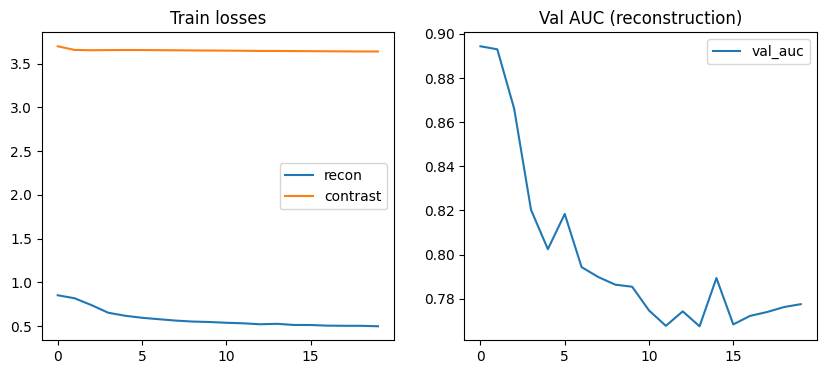

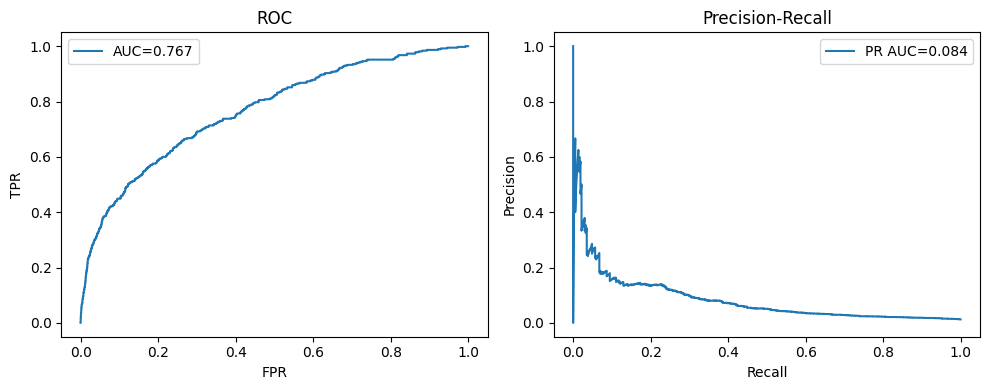

In [ ]:
# Cell 9: Plots
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history['train_recon'], label='recon')
plt.plot(history['train_contrast'], label='contrast')
plt.title("Train losses")
plt.legend()
plt.subplot(1,2,2)
plt.plot(history['val_auc'], label='val_auc')
plt.title("Val AUC (reconstruction)")
plt.legend()
plt.show()

# ROC and PR on test set
from sklearn.metrics import roc_curve

fpr, tpr, _ = roc_curve(test_labels, test_scores)
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(fpr, tpr, label=f"AUC={roc:.3f}")
plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title("ROC"); plt.legend()
plt.subplot(1,2,2)
plt.plot(recall, precision, label=f"PR AUC={pr_auc:.3f}")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Precision-Recall"); plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
# Cell 10: Save artifacts
model_dir = Path("/content/models")
model_dir.mkdir(exist_ok=True)
torch.save(model_ae.state_dict(), model_dir / "transformer_ae.pth")
torch.save(gen.state_dict(), model_dir / "gan_gen.pth")
torch.save(disc.state_dict(), model_dir / "gan_disc.pth")
import joblib
joblib.dump(scaler, model_dir / "scaler.pkl")
print("Saved models to", model_dir)

Saved models to models
